# **Custom Playing Card Dataset**
Dataset preparation

## 1. Configuration parameters

Parameters to be configured:
- `CUSTOM_DATASET_NAME`: name of the dataset which will be created. A folder with this name will be created
- `K`: Number of folds to be created, to perform K-Fold Cross Validation
- `VALID_PERC`: Percentage of the train-valid set to be assigned to the validation set
- `SEED`: Random sedd for reprodicibility

In [1]:
# ===== Configuration parameters

CUSTOM_DATASET_NAME = 'pcd_merge_kfcv'

# Number of folds
K = 5

# Percentage of train_val data to be assigned to valid
VALID_PERC = 0.20

# random seed
SEED = 42

# Dataset to be merged
DATASET_NAMES = ["pcd_src_k", "pcd_src_r"]

# Set this to True is dataset are downloaded as zip files and not extracted yet
EXTRACT_DATASETS = True

##### Directories definition

In [2]:
# ===== DIR_ROOT, DIR_DATASETS, DIR_DATASETS_ORIG

from pathlib import Path
DIR_ROOT = Path.cwd().parent
DIR_DATASETS = DIR_ROOT / "datasets"
DIR_DATASETS_ORIG = DIR_DATASETS / "original"

OUTPUT_DIR = DIR_DATASETS / CUSTOM_DATASET_NAME

## 2. Exploration

### 2.A. Dataset directory structure

In [6]:
from collections import defaultdict

def extract_dir_tree(dataset):
    tree = {}
    for dirpath in sorted(p for p in dataset.rglob("*") if p.is_dir()):
        files = [f for f in dirpath.iterdir() if f.is_file()]
        if not files:
            continue
    
        counts = defaultdict(int)
        for f in files:
            ext = f.suffix.lower() if f.suffix else "no_ext"
            counts[ext] += 1
    
        node = tree
        for part in dirpath.relative_to(dataset).parts:
            node = node.setdefault(part, {})
    
        node["counts"] = dict(counts)
    
    return {dataset.name: tree}

def print_tree(node, prefix=""):
    items = [(k, v) for k, v in node.items() if k != "counts"]

    for i, (name, child) in enumerate(items):
        last = i == len(items) - 1
        branch = "└── " if last else "├── "

        print(f"{prefix}{branch}{name}/")

        counts = child.get("counts", {})
        for ext, n in sorted(counts.items()):
            ext_prefix = prefix + ("    " if last else "│   ")
            print(f"{ext_prefix}├── *{ext} [{n}]")

        print_tree(
            child,
            prefix + ("    " if last else "│   ")
        )

In [7]:
# ===== Print structure of datasets

for ds in DATASETS:
    
    # Extract structure
    dataset_kagg_tree = extract_dir_tree(ds)
    
    # Print structure
    print_tree(dataset_kagg_tree)

    print("\n\n")

└── pcd_src_k/
    ├── test/
    │   ├── images/
    │   │   ├── *.jpg [2000]
    │   └── labels/
    │       ├── *.txt [2000]
    ├── train/
    │   ├── images/
    │   │   ├── *.jpg [14000]
    │   └── labels/
    │       ├── *.txt [14000]
    └── valid/
        ├── images/
        │   ├── *.jpg [4000]
        └── labels/
            ├── *.txt [4000]



└── pcd_src_r/
    ├── test/
    │   ├── images/
    │   │   ├── *.jpg [1010]
    │   └── labels/
    │       ├── *.txt [1010]
    ├── train/
    │   ├── images/
    │   │   ├── *.jpg [7070]
    │   └── labels/
    │       ├── *.txt [7070]
    └── valid/
        ├── images/
        │   ├── *.jpg [2020]
        └── labels/
            ├── *.txt [2020]





## 3. Dataset preparation

In this section the selected datasets are merged and then splitted in order to be able to perform K-Fold Cross Validation.

The final dataset will have the following structure:
```text
dataset_name/
├── images/
├── labels/
├── splits/
└── yamls/
```

Where:
- ```images/```: contains the set of all images provided by the dataset
- ```labels/```: contains the set of all labels provided by the dataset
- ```splits/```: contains .txt files where the separation in folds and train/val/test split are defined. For each fold *i* three files are created:
    1) `fold_i_train.txt`: list of filenames of all images assigned to the *train* set for the i<sup>th</sup> fold
    2) `fold_i_val.txt`: list of filenames of all images assigned to the *valid* set for the i<sup>th</sup> fold
    3) `fold_i_test.txt`: list of filenames of all images assigned to the *test* set for the i<sup>th</sup> fold
- ```yamls/```: contains the .yaml file used by YOLO during training:
  - For each fold *i* a file `fold_i.yaml` is created

### 3.A Setup

#### 3.A.1 Imports

In [8]:
# ===== Various imports

import os
import re
import yaml
import shutil
import random
from pathlib import Path
from collections import defaultdict
from math import ceil

#### 3.A.2 Class names

##### Class definition comparison

The number of classes (*NC*) and class names (*NAMES*) are taken from the *data.yaml* file of the datasets.
The two datasets we chose have the same number of classes and the same logical classes defined, in the same order
> With 'same logical classes' we mean that the classes written into NAMES represent the same combinations of rank and suit. The only difference in the two original data.yaml is that one dataset has the card suit written in upper case (*C* / *D* / *H* / *S* ), while the other has them in lower case (*c* / *d* / *h* / *s* )

The compatibility of the two data.yamls can be seen in the following snippets:

In [9]:
yamls = []

for ds_name in DATASET_NAMES:
    print(f"=== Analyzing: {ds_name}/")

    yaml_path = DIR_DATASETS / ds_name / 'data.yaml'
    
    with open(str(yaml_path)) as s:
        try:
            yaml_content = yaml.safe_load(s)
        except yaml.YAMLError as exc:
            print(exc)


    if yaml_content is not None:
        yamls.append(yaml_content)

        nc = yaml_content['nc']
        print(f" - Number of classes: {nc}")
        
        print(f" - Classes:")
        for i in range(0, nc, 4):
            print(f"    {yaml_content['names'][i:i+4]}")
        print("\n")

=== Analyzing: pcd_src_k/
 - Number of classes: 52
 - Classes:
    ['10c', '10d', '10h', '10s']
    ['2c', '2d', '2h', '2s']
    ['3c', '3d', '3h', '3s']
    ['4c', '4d', '4h', '4s']
    ['5c', '5d', '5h', '5s']
    ['6c', '6d', '6h', '6s']
    ['7c', '7d', '7h', '7s']
    ['8c', '8d', '8h', '8s']
    ['9c', '9d', '9h', '9s']
    ['Ac', 'Ad', 'Ah', 'As']
    ['Jc', 'Jd', 'Jh', 'Js']
    ['Kc', 'Kd', 'Kh', 'Ks']
    ['Qc', 'Qd', 'Qh', 'Qs']


=== Analyzing: pcd_src_r/
 - Number of classes: 52
 - Classes:
    ['10C', '10D', '10H', '10S']
    ['2C', '2D', '2H', '2S']
    ['3C', '3D', '3H', '3S']
    ['4C', '4D', '4H', '4S']
    ['5C', '5D', '5H', '5S']
    ['6C', '6D', '6H', '6S']
    ['7C', '7D', '7H', '7S']
    ['8C', '8D', '8H', '8S']
    ['9C', '9D', '9H', '9S']
    ['AC', 'AD', 'AH', 'AS']
    ['JC', 'JD', 'JH', 'JS']
    ['KC', 'KD', 'KH', 'KS']
    ['QC', 'QD', 'QH', 'QS']




In [10]:
# Print all classes
for class_idx in range(yamls[0]['nc']):
    class_names = []

    # Load all class names for the i-th class
    for file_idx in range(len(yamls)):
        cls_name = yamls[file_idx]['names'][class_idx]
        class_names.append(cls_name)

    # Lowrcase all class names
    classes_lower = [c.lower() for c in class_names]
    match = "MATCH" if len(set(classes_lower)) == 1 else "NO MATCH"

    print(" | ".join(class_names + [match]))

10c | 10C | MATCH
10d | 10D | MATCH
10h | 10H | MATCH
10s | 10S | MATCH
2c | 2C | MATCH
2d | 2D | MATCH
2h | 2H | MATCH
2s | 2S | MATCH
3c | 3C | MATCH
3d | 3D | MATCH
3h | 3H | MATCH
3s | 3S | MATCH
4c | 4C | MATCH
4d | 4D | MATCH
4h | 4H | MATCH
4s | 4S | MATCH
5c | 5C | MATCH
5d | 5D | MATCH
5h | 5H | MATCH
5s | 5S | MATCH
6c | 6C | MATCH
6d | 6D | MATCH
6h | 6H | MATCH
6s | 6S | MATCH
7c | 7C | MATCH
7d | 7D | MATCH
7h | 7H | MATCH
7s | 7S | MATCH
8c | 8C | MATCH
8d | 8D | MATCH
8h | 8H | MATCH
8s | 8S | MATCH
9c | 9C | MATCH
9d | 9D | MATCH
9h | 9H | MATCH
9s | 9S | MATCH
Ac | AC | MATCH
Ad | AD | MATCH
Ah | AH | MATCH
As | AS | MATCH
Jc | JC | MATCH
Jd | JD | MATCH
Jh | JH | MATCH
Js | JS | MATCH
Kc | KC | MATCH
Kd | KD | MATCH
Kh | KH | MATCH
Ks | KS | MATCH
Qc | QC | MATCH
Qd | QD | MATCH
Qh | QH | MATCH
Qs | QS | MATCH


##### Class names

As we can see from the previous snippet, the same set of logical classes are defined in the same order. This allows us to avoid the task of chaning the label index of all label.txt files of one dataset to match the other's definitions.

In [11]:
# Number of classes and classes
NC = 52
NAMES = [
    '10c', '10d', '10h', '10s', 
    '2c', '2d', '2h', '2s', 
    '3c', '3d', '3h', '3s', 
    '4c', '4d', '4h', '4s', 
    '5c', '5d', '5h', '5s', 
    '6c', '6d', '6h', '6s', 
    '7c', '7d', '7h', '7s', 
    '8c', '8d', '8h', '8s', 
    '9c', '9d', '9h', '9s', 
    'Ac', 'Ad', 'Ah', 'As', 
    'Jc', 'Jd', 'Jh', 'Js', 
    'Kc', 'Kd', 'Kh', 'Ks', 
    'Qc', 'Qd', 'Qh', 'Qs'
]

#### 3.A.3 Dataset folders setup

In [12]:
# ===== Directory setup and fold references

OUT_IMAGES = OUTPUT_DIR / "images"
OUT_LABELS = OUTPUT_DIR / "labels"
OUT_SPLITS = OUTPUT_DIR / "splits"
OUT_YAMLS  = OUTPUT_DIR / "yamls"

for d in [OUT_IMAGES, OUT_LABELS, OUT_SPLITS, OUT_YAMLS]:
    d.mkdir(parents=True, exist_ok=True)

print(f"Output directory: {OUTPUT_DIR.resolve()}")

Output directory: /workspace/datasets/pcd_merge_kfcv


### 3.B Image repartition

#### 3.B.1 Merge of chosen datasets

In this initial phase the (two) chosen dataset are merged into a single pool of images (`all_images`)

We loop over both dataset, and over their three splits *train*, *valid* and *test*:
- Every image found is copied to a new folder (`OUTPUT_DIR / images`)
- The label file associated with each image is copied to a new folder (`OUTPUT_DIR / labels`)
- The reference to every image found is kept into a single list `all_images`

In [13]:
# ===== collect_split function

IMG_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tiff", ".tif", ".webp"}

def collect_split(dataset_path: Path, split: str, images_only: bool = True):
    """ Return images paths, for all images of a given split"""

    # Images directory
    img_dir = dataset_path / split / "images"
    if not img_dir.exists():
        return []

    # Return image list (also filter only images)
    if images_only:
        return sorted(
            p for p in img_dir.iterdir()
            if p.is_file() and p.suffix.lower() in IMG_EXTENSIONS
        )

    # Return image list
    else:
        return sorted(
            p for p in img_dir.iterdir()
            if p.is_file()
        )

In [14]:
# ===== add_to_output function

def add_to_output(
    src_img: Path,
    dataset_name: str,
    dst_img_dir: Path,
    dst_lbl_dir: Path,
    src_lbl_dir: Path,
):
    """
    Copies image and relative label to output directory.
    Returns image filename, absolute path
    """
    
    # 1) Construct image and label file names
    prefix = dataset_name + "__"
    dst_name = prefix + src_img.name
    dst_img  = dst_img_dir / dst_name
    dst_lbl  = dst_lbl_dir / (prefix + src_img.stem + ".txt")

    if not src_img.exists():
        raise FileNotFoundError(f"Image not found: {src_img}")

    # 2) Search for corresponding label
    src_lbl = src_lbl_dir / (src_img.stem + ".txt")
    if not src_lbl.exists():
        raise FileNotFoundError(f"Label not found: {src_lbl}")

    # 3) Copy image
    if not dst_img.exists():
        shutil.copy2(src_img, dst_img)
        
    # 4) copy label file
    if not dst_lbl.exists():
        shutil.copy2(src_lbl, dst_lbl)

    return str(dst_img)

In [15]:
# ===== Collection of all images and labels into a single pool
all_images = []

# Loop over all chosen datasets
for ds_name in DATASET_NAMES:

    # Get Dataset root
    ds_path = DIR_DATASETS / ds_name
    print(f"Collecting: {ds_name}")

    # Collect from all three splits
    for split_name in ["train", "valid", "test"]:

        # Just get reference list to all images
        imgs = collect_split(ds_path, split_name)

        # Construct relative labels folder path
        label_dir = ds_path / split_name / "labels"

        # For every found image
        for img in imgs:

            # 1) Physical copy of the image into the new dataset folder
            dst_name = add_to_output(

                # image path
                img, 

                # to prepend the original dataset name to teh image name
                ds_name, 

                # Destination folders
                OUT_IMAGES, OUT_LABELS, 

                # Source labels folder
                label_dir
            )

            # 2) Append image filename to list of all images
            all_images.append(dst_name)

        print(f"  {split_name:<6}: {len(imgs)} images")

print(f"\nTotal images collected: {len(all_images)}")

Collecting: pcd_src_k
  train : 14000 images
  valid : 4000 images
  test  : 2000 images
Collecting: pcd_src_r
  train : 7070 images
  valid : 2020 images
  test  : 1010 images

Total images collected: 30100


#### 3.B.2 Division in folds

The constructed pool of images (`all_images`) if divided into **K** folds:
- The pool is randomly shuffled
- The pool is divided into K buckets `fold_buckets`
  - Each first-level list (`fold_buckets[i]`) is a list of the images assigned to the *i<sup>th</sup>* folder

In [16]:
# ===== chunk_list function

def chunk_list(lst: list, k: int):
    """
    Split a list (lst) into k chunks as even as possible.

    If len(lst) is not divisible by k, it assigns an extra element
    to the first [len(lst) % k] chunks
    """

    # Get list len
    n = len(lst)

    # Get the (minimum) size of each chunk and the reminder
    size = n // k
    rem = n % k

    chunks = []
    start = 0
    
    # Assign images to all chunks
    for i in range(k):

        # assign extra image to first chunks
        end = start + size + (1 if i < rem else 0)
        chunks.append(lst[start:end])
        start = end
        
    return chunks

In [17]:
# ===== Splitting of constructed pool into K folds

# fold_buckets[fold_index] = list of image names of the given buckect / fold
fold_buckets = [ [] for _ in range(K) ]

# Shuffle the images
rng = random.Random(SEED)
rng.shuffle(all_images)

# Divide images into K chunks
fold_buckets = chunk_list(all_images, K)

print(f"\nFold distribution:")
for i, bucket in enumerate(fold_buckets):
    print(f"  Fold {i}: {len(bucket)} images")


Fold distribution:
  Fold 0: 6020 images
  Fold 1: 6020 images
  Fold 2: 6020 images
  Fold 3: 6020 images
  Fold 4: 6020 images


#### 3.B.3 Fold splits generation
Construct the **train / val / test** splits for each fold

In the previous phase `fold_buckets` have been filled. In this phase the buckets are assigned to different splits in each fold, according to the following strategy:

- Starting from K (K = 5 for this example) initial buckets **[0] [1] [2] [3] [4]**
- Loop *K* times, for *i* going from *0* to *K-1*:
  1) Select i<sup>th</sup> bucket **[i]** as the test set
  2) The remaining *K-1* buckets form the train-val set:
     - A fraction `VALID_PERC` of this set is reserved as validation set
     - The remaining part (`1-VALID_PERC`) of this set is is the test set


<details>
    <summary>
        Example, considering buckets ([0] [1] [2] [3] [4]) and VALID_PERC=0.2 
    </summary>

0) Fold 0:
   - Test set: [0]
   - Train set: 80% of ([1] [2] [3] [4])
   - Valid set: 20% of ([1] [2] [3] [4])
1) Fold 1:
   - Test set: [1]
   - Train set: 80% of ([0] [2] [3] [4])
   - Valid set: 20% of ([0] [2] [3] [4])
2) Fold 2:
   - Test set: [2]
   - Train set: 80% of ([0] [1] [3] [4])
   - Valid set: 20% of ([0] [1] [3] [4])
3) Fold 3:
   - Test set: [3]
   - Train set: 80% of ([0] [1] [2] [4])
   - Valid set: 20% of ([0] [1] [2] [4])
3) Fold 4:
   - Test set: [4]
   - Train set: 80% of ([0] [1] [2] [3])
   - Valid set: 20% of ([0] [1] [2] [3])

</details>

In [18]:
# ===== Creation of splitted folds

# List of (train, val, test) for each fold
fold_splits = []

rng = random.Random(SEED)

# Loop K times
for fold_index in range(K):

    # Take i^th buckes as test set
    test_names = fold_buckets[fold_index]

    # Collapse all remaining buckets into the train-valid set
    train_val_names = []
    for other_fold in range(1, K):
        train_val_names.extend(fold_buckets[(fold_index + other_fold) % K])

    # Shuffle train-valid set
    rng.shuffle(train_val_names)

    # Calc how many images goes into valid, according to VALID_PERC
    n_val = int(len(train_val_names) * VALID_PERC)
    val_names = train_val_names[:n_val]
    train_names = train_val_names[n_val:]

    # Save into global list
    fold_splits.append((train_names, val_names, test_names))

#### 3.B.4 Text and Yaml files
Construct the .txt and .yaml file for the splits generated in previous phase

For each fold *i* four files are generated:
- Three .txt files:
  - `fold_i_train.txt`: list of filenames of all images assigned to the *train* set for the i<sup>th</sup> fold
  - `fold_i_val.txt`: list of filenames of all images assigned to the *valid* set for the i<sup>th</sup> fold
  - `fold_i_test.txt`: list of filenames of all images assigned to the *test* set for the i<sup>th</sup> fold
- A .yaml file:
  - `fold_i.yaml`: main data configuration file used by YOLO during
 
An example of a .yaml file content:
```yaml
path: /workspace/datasets/dataset_name
train: splits/fold_i_train.txt
val: splits/fold_i_val.txt
test: splits/fold_i_test.txt
nc: 52
names:
- 10c
- 10h
...
- Qs
```

In [19]:
import yaml

# Absolute path, to be written into 'path' field
DATASET_ABS = OUTPUT_DIR.resolve()

# Loop over all splits
for fold_index, (train_names, val_names, test_names) in enumerate(fold_splits):

    ### 1) Create .txt splits files

    # Create txt files
    test_file  = OUT_SPLITS / f"fold_{fold_index}_test.txt"
    val_file   = OUT_SPLITS / f"fold_{fold_index}_val.txt"
    train_file = OUT_SPLITS / f"fold_{fold_index}_train.txt"

    # Write image lists into their corresponding file
    test_file.write_text("\n".join(test_names)  + "\n")
    val_file.write_text("\n".join(val_names)    + "\n")
    train_file.write_text("\n".join(train_names) + "\n")

    ### 2) Create the data.yaml file

    # Create the yaml content
    yaml_data = {
        "path"  : str(DATASET_ABS),
        "train" : f"splits/fold_{fold_index}_train.txt",
        "val"   : f"splits/fold_{fold_index}_val.txt",
        "test"  : f"splits/fold_{fold_index}_test.txt",
        "nc"    : NC,
        "names" : NAMES,
    }

    # Write to yamls/fold_i.yaml
    yaml_file = OUT_YAMLS / f"fold_{fold_index}.yaml"
    with open(yaml_file, "w") as f:
        yaml.dump(yaml_data, f, default_flow_style=False, sort_keys=False, allow_unicode=True)

    # Recup print
    print(f"\n  Fold {fold_index}:")
    print(f"    train : {train_file.name} ({len(train_names)} img)")
    print(f"    valid : {val_file.name}   ({len(val_names)} img)")
    print(f"    test  : {test_file.name}   ({len(test_names)} img)")
    print(f"    yaml  : {yaml_file.relative_to(OUTPUT_DIR)}")


  Fold 0:
    train : fold_0_train.txt (19264 img)
    valid : fold_0_val.txt   (4816 img)
    test  : fold_0_test.txt   (6020 img)
    yaml  : yamls/fold_0.yaml

  Fold 1:
    train : fold_1_train.txt (19264 img)
    valid : fold_1_val.txt   (4816 img)
    test  : fold_1_test.txt   (6020 img)
    yaml  : yamls/fold_1.yaml

  Fold 2:
    train : fold_2_train.txt (19264 img)
    valid : fold_2_val.txt   (4816 img)
    test  : fold_2_test.txt   (6020 img)
    yaml  : yamls/fold_2.yaml

  Fold 3:
    train : fold_3_train.txt (19264 img)
    valid : fold_3_val.txt   (4816 img)
    test  : fold_3_test.txt   (6020 img)
    yaml  : yamls/fold_3.yaml

  Fold 4:
    train : fold_4_train.txt (19264 img)
    valid : fold_4_val.txt   (4816 img)
    test  : fold_4_test.txt   (6020 img)
    yaml  : yamls/fold_4.yaml


#### 3.B.5 Final recup

In [20]:
# ===== final recup
print("=" * 5, "Total count", "=" * 50)
print(f"Total image count (in images/) : {len(list(OUT_IMAGES.iterdir()))}")
print(f"Total label count (in labels/) : {len(list(OUT_LABELS.iterdir()))}")
print("\n")

print("=" * 5, "Fold subdivision", "=" * 50)
print(f"Train/Valid/Test subdividion into {K} folds:")

header = f"{'Fold':<6} {'Train':<10} {'Val':<10} {'Test':<10}"
print(header)
print("-" * len(header))

for i, (train_names, val_names, test_names) in enumerate(fold_splits):
    print(f"{i:<6} {len(train_names):<10} {len(val_names):<10} {len(test_names):<10}")
print("\n")

print("=" * 5, "Final folder", "=" * 50)
print(f"Dataset can found at: {OUTPUT_DIR.resolve()}")
print("\n")


===== Total count ==================================================
Total image count (in images/) : 30100
Total label count (in labels/) : 30100



===== Fold subdivision ==================================================
Train/Valid/Test subdividion into 5 folds:
Fold   Train      Val        Test      
---------------------------------------
0      19264      4816       6020      
1      19264      4816       6020      
2      19264      4816       6020      
3      19264      4816       6020      
4      19264      4816       6020      



===== Final folder ==================================================
Dataset can found at: /workspace/datasets/pcd_merge_kfcv





## 4. Splitted dataset overview

Visualize how the classes are splitted among folds and splits

### 4.A Utility functions

#### 4.A.1 Import, print and order definitions

In [21]:
from pathlib import Path
from collections import Counter

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

In [1]:
# Desired order for the rank
VALUE_ORDER = ['A', '2', '3', '4', '5', '6', '7', '8', '9', '10', 'J', 'Q', 'K']

# Desired order for the suit
# hearts, clubs, diamonds, spades
SUIT_ORDER = ['h', 'c', 'd', 's']   

# For pretty print
SUIT_COLORS = {
    'h': '#9b2226',   # dark red : hearts
    'd': '#c1440e',   # dark orange-red : diamonds
    'c': '#1a1a1a',   # near-black : clubs
    's': '#4a4a4a',   # dark gray : spades
}
SUIT_LABELS = {
    'h': '♥ Hearts',
    'd': '♦ Diamonds',
    'c': '♣ Clubs',
    's': '♠ Spades',
}

In [23]:
def _parse_card(name: str) -> tuple[str, str]:
    """Return (value, suit) from a card name like '10h' or 'Ac'."""
    return name[:-1], name[-1]


def _sort_key(name: str) -> tuple[int, int]:
    val, suit = _parse_card(name)
    return SUIT_ORDER.index(suit), VALUE_ORDER.index(val)


SORTED_NAMES = sorted(NAMES, key=_sort_key)
SORTED_SUITS = [_parse_card(n)[1] for n in SORTED_NAMES]
BAR_COLORS = [SUIT_COLORS[s] for s in SORTED_SUITS]

#### 4.A.2 Count bounding box per class
Count BBox per class of a given split .txt file

In [24]:
def count_classes(split_txt: Path, labels_dir: Path) -> list[int]:
    """
    Reads all labels from a split file, count BBox per class
    Returns a list with counts in sorted order.
    """
    counts: Counter = Counter()

    # Fetch all images, loop over all
    lines = split_txt.read_text().splitlines()
    for img_path_str in lines:

        # skip if image not found
        img_path = Path(img_path_str.strip())
        if not img_path_str.strip():
            continue

        # Get corresponding label
        lbl_path = labels_dir / (img_path.stem + ".txt")
        if not lbl_path.exists():
            print(f"label not found: {lbl_path}")
            continue

        # Loop over all BBoxes present in the label file
        for line in lbl_path.read_text().splitlines():
            parts = line.strip().split()
            if not parts:
                continue

            # first 'part' is just the class index
            class_idx = int(parts[0])
            counts[NAMES[class_idx]] += 1

    # Return class count BUT orderd by the desired order
    return [counts.get(name, 0) for name in SORTED_NAMES]

#### 4.A.3 Get BBox class count for every fold-split

In [25]:
def load_fold_counts(
    splits_dir: Path,
    labels_dir: Path,
    k: int,
) -> list[dict[str, list[int]]]:
    """
    Load bbox counts for every fold and split.

    Returns a list of k dicts, each with keys 'train', 'val', 'test'
    mapping to a list[int] of length len(SORTED_NAMES).
    """
    folds = []
    for fold_idx in range(K):
        print(f"Counting fold {fold_idx}...")
        fold_counts = {}
        for split in ("train", "val", "test"):
            txt = splits_dir / f"fold_{fold_idx}_{split}.txt"
            if not txt.exists():
                print(f"missing split file: {txt}")
                fold_counts[split] = [0] * len(SORTED_NAMES)
            else:
                fold_counts[split] = count_classes(txt, labels_dir)
        folds.append(fold_counts)
    return folds

#### 4.A.4 Plotting function

In [ ]:
def _x_tick_labels(names: list[str]) -> list[str]:
    """Show only the Ace label on the x-axis; blank everything else."""
    labels = []
    for name in names:
        val, _ = _parse_card(name)
        labels.append('A' if val == 'A' else '')
    return labels


def plot_fold(
    fold_idx: int,
    fold_counts: dict[str, list[int]],
    save_path: Path | None = None,
) -> None:
    """
    Plot one figure with three subplots (train / val / test) for a given fold.
    """
    split_titles = {'train': 'Train', 'val': 'Validation', 'test': 'Test'}
    splits = ['train', 'val', 'test']
    n = len(SORTED_NAMES)
    x = np.arange(n)

    fig, axes = plt.subplots(
        1, 3,
        figsize=(18, 4.5),
        sharey=False,
    )

    fig.suptitle(f'Fold {fold_idx} - class distribution', fontsize=13, fontweight='500', y=1.01)

    # Legend patches (one per suit)
    legend_patches = [
        mpatches.Patch(color=SUIT_COLORS[s], label=SUIT_LABELS[s])
        for s in SUIT_ORDER
    ]
    fig.legend(
        handles=legend_patches,
        loc='upper right',
        ncol=4,
        fontsize=9,
        frameon=False,
        bbox_to_anchor=(1.0, 1.0),
    )
    fig.text(
        0.995, 0.94,
        'Column order within each suit:  A  2  3  4  5  6  7  8  9  10  J  Q  K',
        ha='right', va='top',
        fontsize=8, color='#888888',
    )

    for ax, split in zip(axes, splits):
        counts = fold_counts[split]
        total  = sum(counts)

        bars = ax.bar(x, counts, color=BAR_COLORS, width=0.8, linewidth=0)
        
        for bar, color in zip(bars, BAR_COLORS):
            ax.bar(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height(),
                width=bar.get_width(),
                color=color,
                linewidth=0,
                zorder=3,
            )

        ax.set_title(split_titles[split], fontsize=11, fontweight='500', pad=6)
        ax.set_xticks(x)
        ax.set_xticklabels(_x_tick_labels(SORTED_NAMES), fontsize=8)
        ax.tick_params(axis='x', length=0)
        ax.yaxis.set_tick_params(labelsize=8)
        ax.set_ylabel('BBox count', fontsize=8)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_color('#cccccc')
        ax.spines['bottom'].set_color('#cccccc')
        ax.yaxis.grid(True, color='#e8e8e8', linewidth=0.8, zorder=0)
        ax.set_axisbelow(True)

        # Total bbox count as caption
        ax.text(
            0.99, 0.97,
            f'{total:,} bbox',
            transform=ax.transAxes,
            ha='right', va='top',
            fontsize=8, color='#888888',
        )

    fig.tight_layout()

    # Save images
    fig.savefig(save_path, dpi=150, bbox_inches='tight')
    print(f"  Saved to {save_path}")

    # show image
    plt.show()

    plt.close(fig)

### 4.B Visualization

Counting fold 0...
Counting fold 1...
Counting fold 2...
Counting fold 3...
Counting fold 4...
  Saved to /workspace/datasets/pcd_merge_kfcv/plots/fold_0_distribution.png


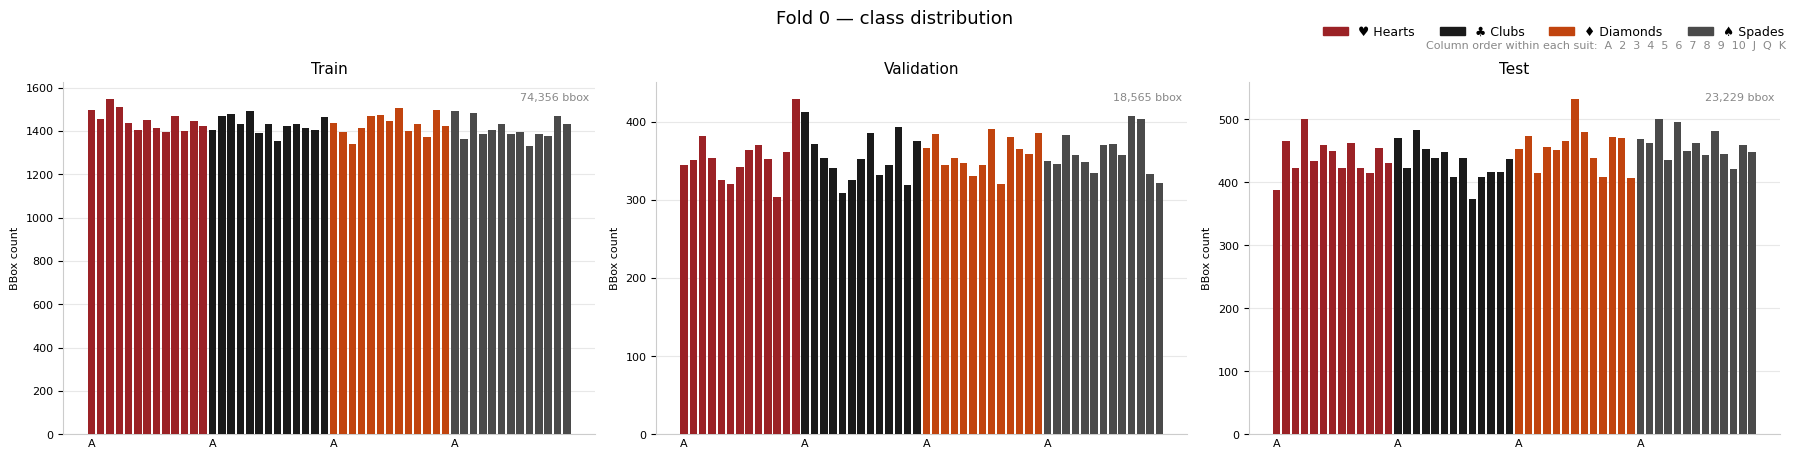

  Saved to /workspace/datasets/pcd_merge_kfcv/plots/fold_1_distribution.png


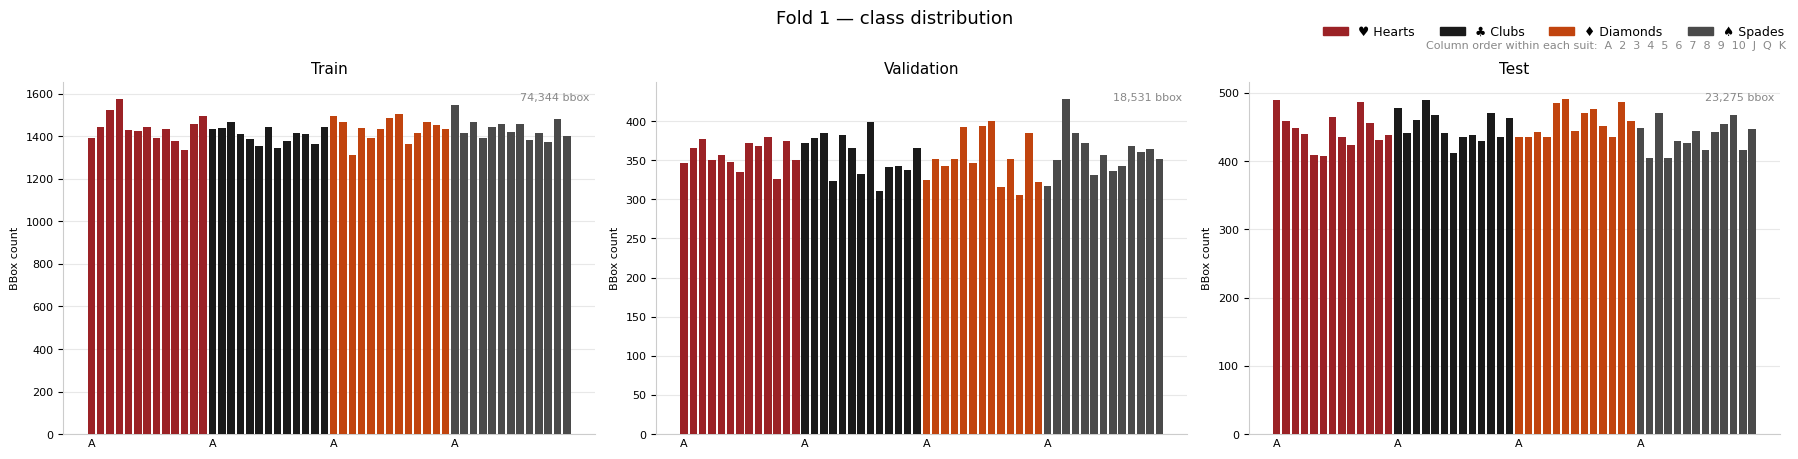

  Saved to /workspace/datasets/pcd_merge_kfcv/plots/fold_2_distribution.png


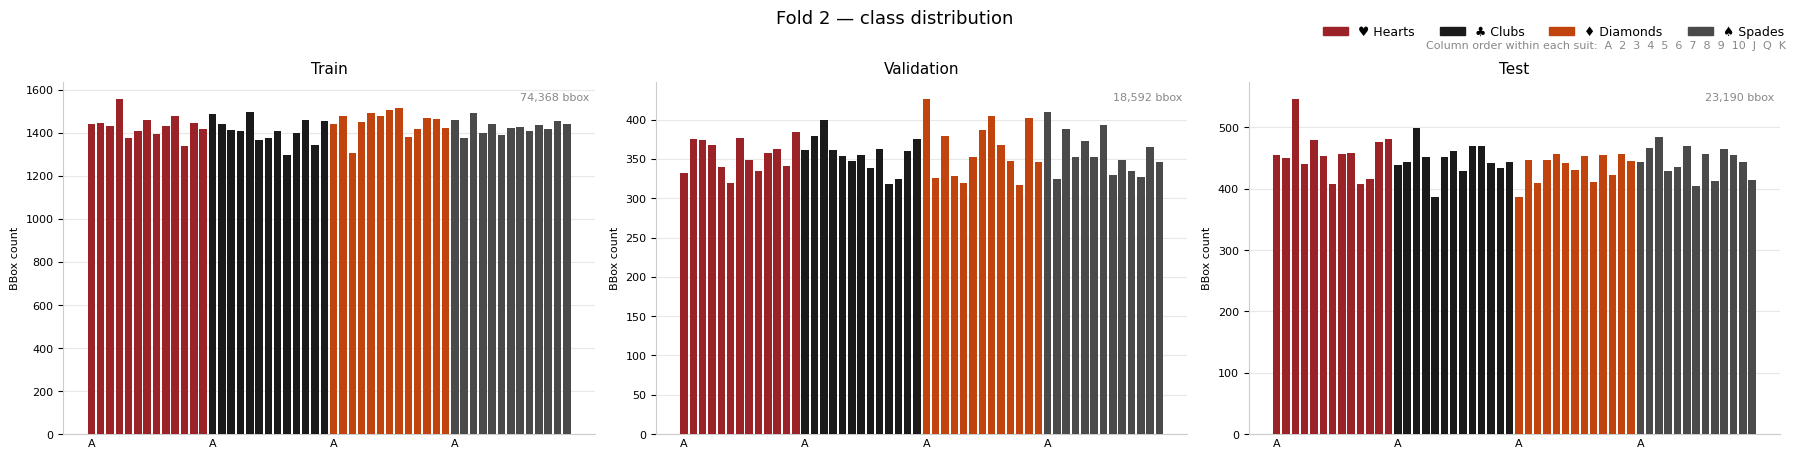

  Saved to /workspace/datasets/pcd_merge_kfcv/plots/fold_3_distribution.png


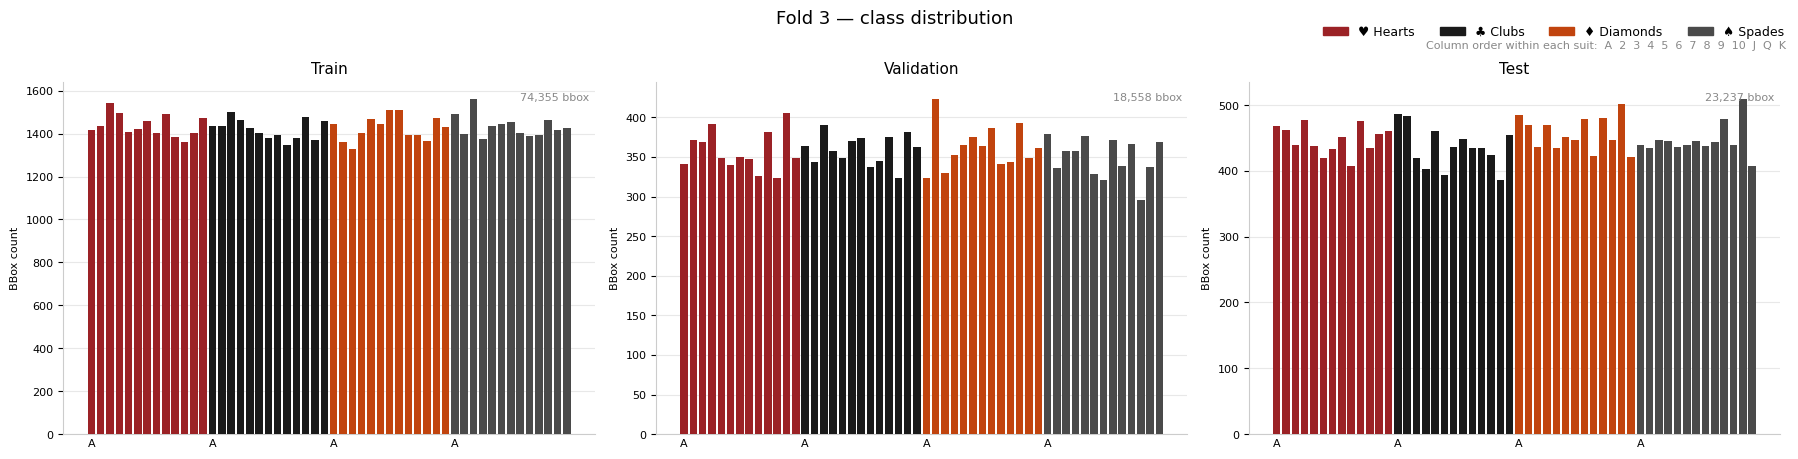

  Saved to /workspace/datasets/pcd_merge_kfcv/plots/fold_4_distribution.png


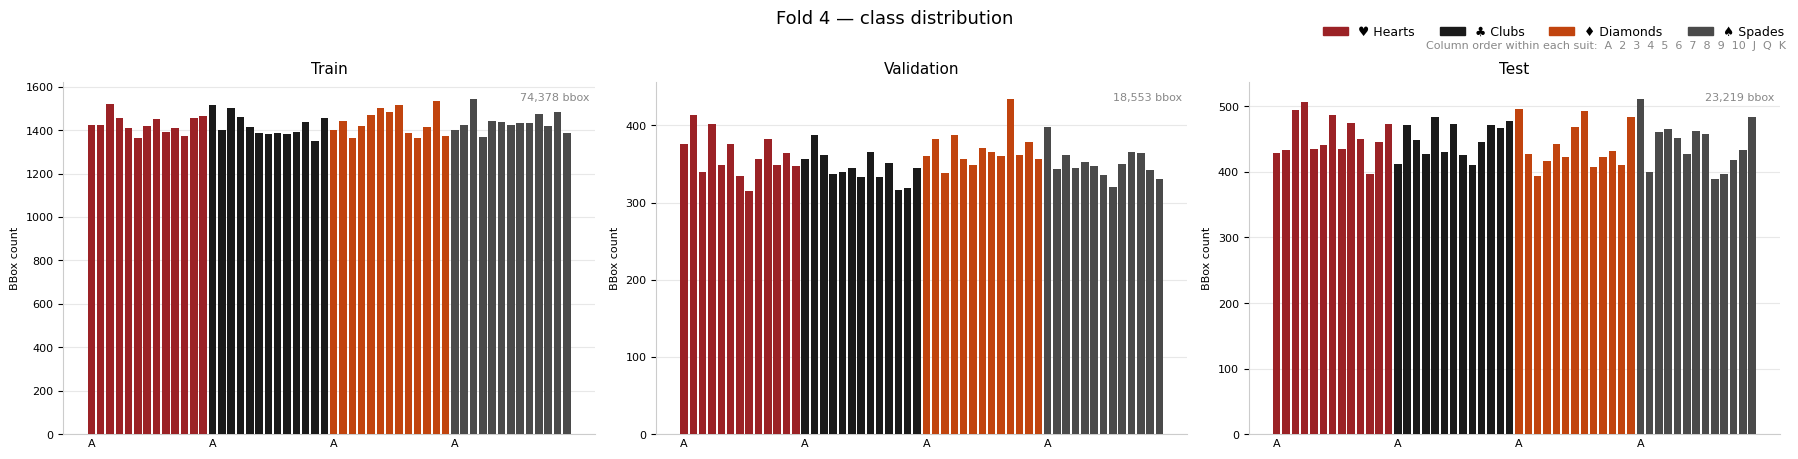

In [27]:
# ===== Visualization

folds = load_fold_counts(OUT_SPLITS, OUT_LABELS, K)

OUT_PLOTS = OUTPUT_DIR / "plots"
OUT_PLOTS.mkdir(parents=True, exist_ok=True)

for fold_idx, fold_counts in enumerate(folds):
    save_path = OUT_PLOTS / f"fold_{fold_idx}_distribution.png"
    plot_fold(fold_idx, fold_counts, save_path=save_path)

## 5. Dataset compression

Useful if dataset needs to be exported

In [28]:
COMPRESS_TO_ZIP = True
COMPRESS_TO_TARXZ = False

In [29]:
# ===== Compression (of merged dataset)

import shutil
import tarfile

zip_path = OUTPUT_DIR.with_suffix(".zip")
tarxz_path = OUTPUT_DIR.with_suffix(".tar.xz")

source_dir = OUTPUT_DIR
output_base = OUTPUT_DIR

# zip
if COMPRESS_TO_ZIP:
    shutil.make_archive(
        base_name=str(OUTPUT_DIR),
        format="zip",
        root_dir=str(OUTPUT_DIR)
    )
    print(f"Created: {zip_path}")

# tar
if COMPRESS_TO_TARXZ:
    with tarfile.open(tarxz_path, "w:xz") as tar:
        tar.add(OUTPUT_DIR, arcname=OUTPUT_DIR.name)

    print(f"Created: {tarxz_path}")

Created: /workspace/datasets/pcd_merge_kfcv.zip
